# BT4012 Kaggle Competition: Detecting Illicit Bitcoin Transactions

This notebook shows the full path from my first submission to my final model.
Every step trains a model, writes the submission file I uploaded to Kaggle, and
notes the public leaderboard score it got. The scores are what I used to decide
what to keep and what to drop.

**Kaggle progression at a glance**

| Step | Submission file | Idea tested | Public AUC |
|---|---|---|---|
| 1 | submission_main.csv | MLP-heavy blend (best on validation) | 0.92846 |
| 2 | submission_lgb_notime.csv | LightGBM alone, time-proxy features removed | 0.94401 |
| 3 | submission_rf_notime.csv | Random Forest | 0.91961 |
| 4 | submission_lgb_goss.csv | Best LightGBM from the validation tuning sweep | 0.94320 |
| 5 | submission_lgb_flexible.csv | Flexible instead of cautious LightGBM | 0.94811 |
| 6 | submission_flex_ensemble.csv | Ensemble of flexible models + recent training windows | 0.95268 |
| 7 | submission_graph_1hop.csv | + 1-hop neighbour features | 0.95696 |
| 8 | **submission_graph_ensemble.csv** | **+ 2-hop neighbour features (final model)** | **0.95915** |
| 9 | submission_graph_plus_std.csv | + neighbour spread (extension, rejected) | 0.95885 |

**Data used:** only the four competition files. Put them in `./data/`.
Running everything takes about 30 minutes on a laptop.

In [1]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt

import lightgbm as lgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import QuantileTransformer
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")

DATA_DIR = "./data/"
OUT_DIR = "./submissions/"
os.makedirs(OUT_DIR, exist_ok=True)
N_JOBS = 2
start_time = time.time()

In [2]:
# Load the competition files
train_raw = pd.read_csv(DATA_DIR + "train.csv")
test = pd.read_csv(DATA_DIR + "test.csv")
edges = pd.read_csv(DATA_DIR + "txs_edgelist.csv")
sample = pd.read_csv(DATA_DIR + "sample_submission.csv")

print("train:", train_raw.shape)
print("test:", test.shape)
print("edges:", edges.shape)

# The 165 anonymised feature columns
FEATS = [c for c in train_raw.columns if c.startswith("feat_")]

# Elliptic layout: the first 93 features describe the transaction itself,
# the remaining 72 are aggregates over its neighbours
LOCAL = FEATS[:93]

train: (141772, 168)
test: (15329, 168)
edges: (234355, 2)


# 1. Exploratory Data Analysis

## 1.1 Labels and class balance

In [3]:
print(train_raw["label"].value_counts(dropna=False))

# Only labelled rows can be used for training
lab = train_raw[train_raw["label"].notna()].reset_index(drop=True)

print("\nshare of training rows with a label:", round(len(lab) / len(train_raw), 3))
print("share of labelled rows that are illicit:", round(lab["label"].mean(), 3))

label
NaN    110537
0.0     27591
1.0      3644
Name: count, dtype: int64

share of training rows with a label: 0.22
share of labelled rows that are illicit: 0.117


Only 22% of training transactions have a label, and only 11.7% of those are
illicit. The classes are heavily imbalanced, which is why the competition uses
ROC-AUC rather than accuracy.

## 1.2 How labels change over time

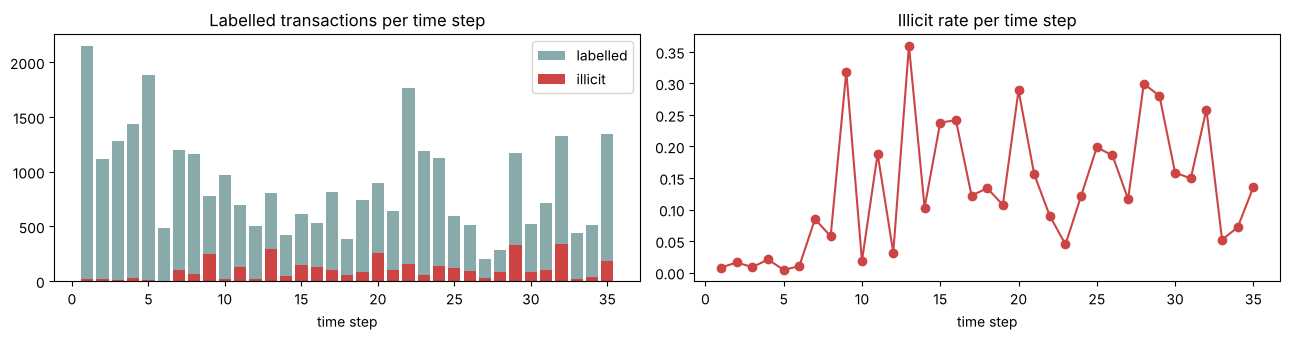

train time steps: 1 to 35
test time steps:  36 to 49
lowest illicit rate:  0.4% (step 5)
highest illicit rate: 36.0% (step 13)


In [4]:
per_step = lab.groupby("time_step")["label"].agg(["size", "sum", "mean"])
per_step.columns = ["n_labelled", "n_illicit", "illicit_rate"]

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].bar(per_step.index, per_step["n_labelled"], color="#8aa", label="labelled")
ax[0].bar(per_step.index, per_step["n_illicit"], color="#c44", label="illicit")
ax[0].set_title("Labelled transactions per time step")
ax[0].set_xlabel("time step")
ax[0].legend()

ax[1].plot(per_step.index, per_step["illicit_rate"], marker="o", color="#c44")
ax[1].set_title("Illicit rate per time step")
ax[1].set_xlabel("time step")
plt.tight_layout()
plt.show()

print("train time steps:", train_raw["time_step"].min(), "to", train_raw["time_step"].max())
print("test time steps: ", test["time_step"].min(), "to", test["time_step"].max())

low_step = per_step["illicit_rate"].idxmin()
high_step = per_step["illicit_rate"].idxmax()
print(f"lowest illicit rate:  {per_step.loc[low_step, 'illicit_rate']:.1%} (step {low_step})")
print(f"highest illicit rate: {per_step.loc[high_step, 'illicit_rate']:.1%} (step {high_step})")

The illicit rate swings a lot from step to step (from under 1% to over 30%), and
the test set comes from **later** time steps (36 to 49) than anything in
training. So the model has to work on a future period it has never seen. This
rules out random K-fold cross-validation: it would mix future and past
transactions and give over-optimistic scores.

## 1.3 Structure of the transaction graph

In [5]:
# Which time step each transaction belongs to
step_of = pd.concat([train_raw[["txId", "time_step"]], test[["txId", "time_step"]]])
step_of = step_of.set_index("txId")["time_step"]

src_step = edges["txId1"].map(step_of)
dst_step = edges["txId2"].map(step_of)
both_known = src_step.notna() & dst_step.notna()

print("edges where both transactions are in the files:", round(both_known.mean(), 3))
print("of those, same time step:", round((src_step[both_known] == dst_step[both_known]).mean(), 3))

# Edges that point to a transaction missing from the files
missing_steps = pd.concat([dst_step[src_step.isna()], src_step[dst_step.isna()]])
print("time steps of edges with a missing transaction:", int(missing_steps.min()), "to", int(missing_steps.max()))

edges where both transactions are in the files: 0.751
of those, same time step: 1.0
time steps of edges with a missing transaction: 36 to 49


Two important findings:

1. **Every edge links two transactions in the same time step.** The graph is a
   series of separate snapshots, so graph features never mix information across
   time periods.
2. **In the test period, unlabelled transactions were removed from the files**,
   but their edges are still in the edge list. In training, unlabelled
   transactions are still present. So any neighbour-based feature must count
   only neighbours that would also be visible in the test period: labelled
   training transactions and test transactions. Otherwise the feature would
   mean something different in training and testing.

## 1.4 Simple graph features and how they relate to the label

In [6]:
# Build the full directed graph from the edge list (no labels used)
G = nx.DiGraph()
G.add_edges_from(edges[["txId1", "txId2"]].itertuples(index=False, name=None))

in_deg = dict(G.in_degree())
out_deg = dict(G.out_degree())

# Depth = length of the longest chain of earlier transactions feeding into this one.
# Height = length of the longest chain of later transactions it feeds into.
order = list(nx.topological_sort(G))     # the graph has no cycles, money only moves forward
depth = {n: 0 for n in order}
for n in order:
    for nxt in G.successors(n):
        depth[nxt] = max(depth[nxt], depth[n] + 1)

height = {n: 0 for n in order}
for n in reversed(order):
    for prev in G.predecessors(n):
        height[prev] = max(height[prev], height[n] + 1)

lab["in_degree"] = lab["txId"].map(in_deg)
lab["out_degree"] = lab["txId"].map(out_deg)
lab["dag_depth"] = lab["txId"].map(depth)

print(lab.groupby("label")[["in_degree", "out_degree", "dag_depth"]].mean().round(2))

       in_degree  out_degree  dag_depth
label                                  
0.0         1.83        1.15      12.29
1.0         1.25        0.75       8.33


### Concept drift: the peeling chain

A *peeling chain* is a laundering pattern where funds hop through a long chain
of one-in, one-out transactions, shaving off a little each time. In this graph
it shows up as a large `dag_depth`. The table below shows its meaning **flips
over time**: deep-chain transactions were almost always licit early on, but a
large share are illicit in steps 29 to 35.

In [7]:
depth_bin = pd.cut(lab["dag_depth"], [-1, 2, 5, 10, 20, 10_000], labels=["0-2", "3-5", "6-10", "11-20", ">20"])
period = pd.cut(lab["time_step"], [0, 10, 21, 28, 35], labels=["1-10", "11-21", "22-28", "29-35"])

print("Illicit rate by chain depth (rows) and period (columns)")
print(lab.groupby([depth_bin, period])["label"].mean().unstack().round(3))

Illicit rate by chain depth (rows) and period (columns)
time_step   1-10  11-21  22-28  29-35
dag_depth                            
0-2        0.045  0.220  0.125  0.154
3-5        0.062  0.229  0.131  0.228
6-10       0.050  0.106  0.127  0.091
11-20      0.012  0.062  0.137  0.115
>20        0.007  0.008  0.032  0.382


This is an early warning that patterns learned from old periods may not hold in
later ones. It turned out to be the most important theme of the whole project.

# 2. Data Preprocessing

## 2.1 Removing features that secretly encode time

Some anonymised columns might simply be a disguised time stamp. I check each
feature's correlation with `time_step`, and how much of the test set falls
outside the training range for that feature. No labels are used for this check.

In [8]:
all_rows = pd.concat([lab[["time_step"] + FEATS], test[["time_step"] + FEATS]])

rows = []
for col in FEATS:
    low, high = lab[col].quantile([0.001, 0.999])
    corr_with_time = abs(all_rows[[col, "time_step"]].corr(method="spearman").iloc[0, 1])
    share_outside = ((test[col] < low) | (test[col] > high)).mean()
    rows.append((col, corr_with_time, share_outside))

time_check = pd.DataFrame(rows, columns=["feature", "corr_with_time", "test_share_outside_train_range"])
time_check = time_check.sort_values("test_share_outside_train_range", ascending=False)
print(time_check.head(6).round(3).to_string(index=False))

 feature  corr_with_time  test_share_outside_train_range
feat_101           0.998                           0.996
feat_103           0.995                           0.994
feat_100           0.993                           0.992
feat_107           0.545                           0.075
feat_109           0.611                           0.069
feat_106           0.607                           0.065


In [9]:
# Three features are almost perfectly correlated with time and almost every
# test value is outside the training range: they are time stamps in disguise
TIME_PROXIES = ["feat_100", "feat_101", "feat_103"]
F = [c for c in FEATS if c not in TIME_PROXIES]
print("features kept:", len(F))

# Their median rises in a straight line over time
print(all_rows.groupby("time_step")[TIME_PROXIES].median().iloc[::6].round(2).T)

features kept: 162
time_step    1     7     13    19    25    31    37    43    49
feat_100  -1.46 -1.07 -0.68 -0.30  0.09  0.48  0.87  1.25  1.64
feat_101  -1.49 -1.10 -0.71 -0.31  0.08  0.48  0.87  1.26  1.66
feat_103  -1.49 -1.09 -0.70 -0.31  0.09  0.48  0.87  1.26  1.66


These three columns tell the model *when* a transaction happened, which cannot
generalise to future time steps. I remove them from step 2 onwards (my very first
submission still used them).

## 2.2 Other preprocessing

* **Missing values:** none in the feature columns. Graph features below are set
  to missing (NaN) when a transaction has no visible neighbour, and LightGBM
  handles NaN natively.
* **Scaling:** the features are already normalised. Tree models do not need
  scaling. For the logistic regression and MLP I use a quantile transform
  fitted on the training window only.
* **Class imbalance:** I use AUC for every comparison and keep the natural class
  ratio. A class-weighted LightGBM is tested in the tuning sweep (step 4).

# 3. Validation Setup

Because the test set is in the future, I validate **forward in time**: train on
earlier steps, score on later ones. Three short folds predict the next 5 steps,
and two long folds predict the next 14 steps, the same gap as the real test set
(train on 1 to 35, predict 36 to 49).

| fold | train steps | validation steps |
|---|---|---|
| s21 | 1-20 | 21-25 |
| s26 | 1-25 | 26-30 |
| s31 | 1-30 | 31-35 |
| L18 | 1-17 | 18-31 |
| L22 | 1-21 | 22-35 |

In [10]:
FOLDS = {
    "s21": (20, 21, 25),
    "s26": (25, 26, 30),
    "s31": (30, 31, 35),
    "L18": (17, 18, 31),
    "L22": (21, 22, 35),
}


def rank01(scores):
    # Convert scores to ranks between 0 and 1 so different models can be averaged
    return pd.Series(scores).rank(pct=True).values


def time_cv(data, fit_predict):
    # Train on earlier steps, score on later steps, for each fold
    results = {}
    for name, (train_end, val_start, val_end) in FOLDS.items():
        train_part = data[data["time_step"] <= train_end]
        val_part = data[data["time_step"].between(val_start, val_end)]
        preds = fit_predict(train_part, val_part)
        results[name] = roc_auc_score(val_part["label"], preds)
    scores = np.array(list(results.values()))
    print(f"   short folds {scores[:3].mean():.4f} | long folds {scores[3:].mean():.4f} | all {scores.mean():.4f}")
    return scores.mean()


def save_submission(pred, test_frame, filename):
    # Write a submission file in the same order as sample_submission.csv
    sub = pd.DataFrame({"index": test_frame["index"].values, "target": pred})
    sub = sample[["index"]].merge(sub, on="index", how="left")
    assert len(sub) == len(sample) and sub["target"].notna().all()
    sub.to_csv(OUT_DIR + filename, index=False)
    print("   saved", filename)


CV_RESULTS = {}

In [11]:
# LightGBM settings used throughout

# "Cautious" = small trees, slow learning, heavy regularisation
CAUTIOUS = dict(objective="binary", verbose=-1, n_jobs=N_JOBS,
                learning_rate=0.03, num_leaves=15, min_child_samples=50,
                feature_fraction=0.5, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0)

# "Flexible" = close to LightGBM's defaults: bigger trees, faster learning, no extra penalty
FLEXIBLE = dict(objective="binary", verbose=-1, n_jobs=N_JOBS,
                learning_rate=0.1, num_leaves=31, min_child_samples=20,
                feature_fraction=1.0, bagging_fraction=1.0, bagging_freq=0, lambda_l2=0.0)


def train_lgb(train_part, apply_part, cols, params, rounds, seeds):
    # Train one LightGBM per seed and average their ranked predictions
    preds = []
    for seed in seeds:
        params_seed = dict(params)
        params_seed["seed"] = seed
        model = lgb.train(params_seed, lgb.Dataset(train_part[cols], train_part["label"]), rounds)
        preds.append(rank01(model.predict(apply_part[cols])))
    return np.mean(preds, axis=0)

# 4. Model Development

## Step 1: Baseline comparison and my first submission

I start by comparing a linear model, a neural network (MLP) and LightGBM on the
time folds. For this first round I also include 14 simple graph features (degree,
PageRank, chain depth, how many neighbours are visible).

In [12]:
# 14 simple structural graph features (computed from the edge list only)
pagerank = nx.pagerank(G, max_iter=200)
pagerank_rev = nx.pagerank(G.reverse(copy=False), max_iter=200)
component_size = {}
for comp in nx.weakly_connected_components(G):
    for n in comp:
        component_size[n] = len(comp)

struct = pd.DataFrame({"txId": list(G.nodes())})
struct["g_in"] = struct["txId"].map(in_deg)
struct["g_out"] = struct["txId"].map(out_deg)

# 2-hop reach and neighbour degree statistics
in2, out2, nb_mean, nb_max = [], [], [], []
for n in struct["txId"]:
    preds_, succs_ = list(G.predecessors(n)), list(G.successors(n))
    in2.append(sum(in_deg[p] for p in preds_))
    out2.append(sum(out_deg[s] for s in succs_))
    nb_degrees = [in_deg[x] + out_deg[x] for x in preds_ + succs_]
    nb_mean.append(np.mean(nb_degrees) if nb_degrees else np.nan)
    nb_max.append(np.max(nb_degrees) if nb_degrees else np.nan)
struct["g_in2"], struct["g_out2"] = in2, out2
struct["g_nbdeg_mean"], struct["g_nbdeg_max"] = nb_mean, nb_max

struct["g_comp"] = struct["txId"].map(component_size)
struct["g_pr"] = struct["txId"].map(pagerank)
struct["g_pr_rev"] = struct["txId"].map(pagerank_rev)
struct["g_depth"] = struct["txId"].map(depth)
struct["g_height"] = struct["txId"].map(height)

# How many neighbours are visible (labelled in train, or in test)
visible_ids = set(lab["txId"]) | set(test["txId"])
visible_edges = edges[edges["txId1"].isin(visible_ids) & edges["txId2"].isin(visible_ids)]
vis_in = visible_edges["txId2"].value_counts()
vis_out = visible_edges["txId1"].value_counts()
struct["n_in_vis"] = struct["txId"].map(vis_in).fillna(0)
struct["n_out_vis"] = struct["txId"].map(vis_out).fillna(0)
struct["n_vis_frac"] = (struct["n_in_vis"] + struct["n_out_vis"]) / (struct["g_in"] + struct["g_out"]).clip(lower=1)

STRUCT = [c for c in struct.columns if c != "txId"]
lab = lab.drop(columns=["in_degree", "out_degree", "dag_depth"]).merge(struct, on="txId", how="left")
test_s = test.merge(struct, on="txId", how="left")
print(len(STRUCT), "structural graph features:", STRUCT)

14 structural graph features: ['g_in', 'g_out', 'g_in2', 'g_out2', 'g_nbdeg_mean', 'g_nbdeg_max', 'g_comp', 'g_pr', 'g_pr_rev', 'g_depth', 'g_height', 'n_in_vis', 'n_out_vis', 'n_vis_frac']


In [13]:
def fit_logreg(train_part, apply_part, cols):
    qt = QuantileTransformer(output_distribution="normal", n_quantiles=1000, random_state=0).fit(train_part[cols])
    model = LogisticRegression(C=0.1, max_iter=3000)
    model.fit(qt.transform(train_part[cols]), train_part["label"])
    return model.predict_proba(qt.transform(apply_part[cols]))[:, 1]


def fit_mlp(train_part, apply_part, cols, alpha, seeds):
    # Quantile transform is fitted on the training window only
    qt = QuantileTransformer(output_distribution="normal", n_quantiles=1000, random_state=0).fit(train_part[cols])
    x_train, x_apply = qt.transform(train_part[cols]), qt.transform(apply_part[cols])
    preds = []
    for seed in seeds:
        model = MLPClassifier((256, 64), alpha=alpha, batch_size=256, learning_rate_init=1e-3, max_iter=40,
                              early_stopping=True, n_iter_no_change=5, random_state=seed)
        model.fit(x_train, train_part["label"])
        preds.append(rank01(model.predict_proba(x_apply)[:, 1]))
    return np.mean(preds, axis=0)


print("Logistic regression (165 feats)")
CV_RESULTS["Logistic regression"] = time_cv(lab, lambda a, b: fit_logreg(a, b, FEATS))

print("MLP 256-64 (165 feats + 14 graph feats)")
CV_RESULTS["MLP + graph"] = time_cv(lab, lambda a, b: fit_mlp(a, b, FEATS + STRUCT, 1e-3, (0,)))

print("LightGBM cautious (165 feats)")
CV_RESULTS["LightGBM cautious (165)"] = time_cv(lab, lambda a, b: train_lgb(a, b, FEATS, CAUTIOUS, 400, (0,)))

Logistic regression (165 feats)


   short folds 0.9491 | long folds 0.8750 | all 0.9194
MLP 256-64 (165 feats + 14 graph feats)


   short folds 0.9775 | long folds 0.9430 | all 0.9637
LightGBM cautious (165 feats)


   short folds 0.9817 | long folds 0.9115 | all 0.9536


On the time folds the **MLP looked best**, so my first submission leaned heavily
on it: a blend of 85% MLP (two regularisation strengths) and 15% LightGBM.

In [14]:
# Step 1 submission: 0.85 x MLPs + 0.15 x LightGBM (5 seeds each)
seeds5 = (0, 1, 2, 3, 4)
mlp_a = fit_mlp(lab, test_s, FEATS + STRUCT, 1e-3, seeds5)
mlp_b = fit_mlp(lab, test_s, FEATS + STRUCT, 1e-1, seeds5)
lgb_165 = train_lgb(lab, test_s, FEATS, CAUTIOUS, 400, seeds5)

step1 = 0.85 * (0.5 * mlp_a + 0.5 * mlp_b) + 0.15 * lgb_165
save_submission(rank01(step1), test_s, "submission_main.csv")

   saved submission_main.csv


After submitting, I checked how similar the MLP and LightGBM rankings are on the
test set compared with a validation fold. This only compares the two models'
predictions with each other, so no test labels are needed.

In [15]:
mlp_blend = 0.5 * mlp_a + 0.5 * mlp_b
test_agreement = pd.Series(mlp_blend).corr(pd.Series(lgb_165), method="spearman")

# Same comparison on the long validation fold L22 (train on steps 1-21, predict 22-35)
fold_train = lab[lab["time_step"] <= 21]
fold_val = lab[lab["time_step"].between(22, 35)]
val_mlp = 0.5 * fit_mlp(fold_train, fold_val, FEATS + STRUCT, 1e-3, seeds5) + 0.5 * fit_mlp(fold_train, fold_val, FEATS + STRUCT, 1e-1, seeds5)
val_lgb = train_lgb(fold_train, fold_val, FEATS, CAUTIOUS, 400, seeds5)
val_agreement = pd.Series(val_mlp).corr(pd.Series(val_lgb), method="spearman")

print(f"rank correlation between MLP and LightGBM, validation fold L22: {val_agreement:.2f}")
print(f"rank correlation between MLP and LightGBM, test set:            {test_agreement:.2f}")

rank correlation between MLP and LightGBM, validation fold L22: 0.85
rank correlation between MLP and LightGBM, test set:            0.62


**Kaggle public AUC: 0.92846.** Much worse than the validation suggested. Two
things looked suspicious:

* the model still used the three time-proxy features (Section 2.1)
* the MLP and LightGBM agreed less on the test set than on validation (see the
  rank correlations printed above), suggesting the test period differs from
  anything in my folds

## Step 2: LightGBM alone, without the time proxies

To find out which part failed, I submitted LightGBM on its own with the time
proxies removed.

In [16]:
print("LightGBM cautious (162 feats, no time proxies)")
CV_RESULTS["LightGBM cautious (162)"] = time_cv(lab, lambda a, b: train_lgb(a, b, F, CAUTIOUS, 400, (0,)))

step2 = train_lgb(lab, test_s, F, CAUTIOUS, 400, seeds5)
save_submission(step2, test_s, "submission_lgb_notime.csv")

LightGBM cautious (162 feats, no time proxies)


   short folds 0.9829 | long folds 0.9118 | all 0.9545


   saved submission_lgb_notime.csv


**Kaggle public AUC: 0.94401** (+0.016 over step 1). LightGBM alone clearly beats
the MLP blend, so the MLP was the part that failed on the test period. From here
on I drop the MLP and focus on tree models.

## Step 3: Random Forest

Random Forest is the strongest model reported in the original Elliptic paper, so
I tested it too.

In [17]:
def fit_rf(train_part, apply_part, cols, n_trees=1000):
    model = RandomForestClassifier(n_estimators=n_trees, max_features=50, n_jobs=N_JOBS, random_state=0)
    model.fit(train_part[cols], train_part["label"])
    return model.predict_proba(apply_part[cols])[:, 1]


print("Random Forest (162 feats)")
# 300 trees for validation to save time; the submission uses 1000
CV_RESULTS["Random Forest"] = time_cv(lab, lambda a, b: fit_rf(a, b, F, n_trees=300))

step3 = fit_rf(lab, test_s, F)
save_submission(step3, test_s, "submission_rf_notime.csv")

Random Forest (162 feats)


   short folds 0.9475 | long folds 0.8646 | all 0.9143


   saved submission_rf_notime.csv


**Kaggle public AUC: 0.91961.** Clearly worse than LightGBM (0.944), matching the
validation ranking. LightGBM stays as the main model.

## Step 4: Tuning LightGBM on the validation folds

I ran a tuning sweep on the time folds. Each setting changes one thing from the
cautious LightGBM (tree size, leaf size, feature and row sampling, learning
rate, number of rounds, L1/L2 penalties, class weighting, GOSS sampling).
Every setting uses 3 seeds.

In [18]:
# Each entry: (parameter changes from CAUTIOUS, number of rounds)
SWEEP = {
    "cautious (reference)": ({}, 400),
    "7 leaves": ({"num_leaves": 7}, 400),
    "31 leaves": ({"num_leaves": 31}, 400),
    "min 20 samples per leaf": ({"min_child_samples": 20}, 400),
    "min 100 samples per leaf": ({"min_child_samples": 100}, 400),
    "min 200 samples per leaf": ({"min_child_samples": 200}, 400),
    "30% of features per tree": ({"feature_fraction": 0.3}, 400),
    "80% of features per tree": ({"feature_fraction": 0.8}, 400),
    "200 rounds": ({}, 200),
    "learning rate 0.015, 800 rounds": ({"learning_rate": 0.015}, 800),
    "extra trees, 800 rounds": ({"extra_trees": True}, 800),
    "L2 penalty 10": ({"lambda_l2": 10}, 400),
    "L1 penalty 1": ({"lambda_l1": 1}, 400),
    "63 histogram bins": ({"max_bin": 63}, 400),
    "balanced bagging": ({"pos_bagging_fraction": 1.0, "neg_bagging_fraction": 0.5, "bagging_fraction": 1.0}, 400),
    "class-weighted (is_unbalance)": ({"is_unbalance": True}, 400),
    "GOSS sampling": ({"data_sample_strategy": "goss", "bagging_fraction": 1.0, "bagging_freq": 0}, 400),
}

sweep_rows = []
for name, (changes, rounds) in SWEEP.items():
    params = dict(CAUTIOUS)
    params.update(changes)
    print(name)
    score = time_cv(lab, lambda a, b: train_lgb(a, b, F, params, rounds, (0, 1, 2)))
    sweep_rows.append((name, score))

sweep = pd.DataFrame(sweep_rows, columns=["setting", "CV AUC (all folds)"])
sweep = sweep.sort_values("CV AUC (all folds)", ascending=False).reset_index(drop=True)
print()
print(sweep.round(4).to_string(index=False))

best_score = sweep["CV AUC (all folds)"].iloc[0]
close = (sweep["CV AUC (all folds)"] >= best_score - 0.002).sum()
print(f"\nbest: {sweep['setting'].iloc[0]} ({best_score:.4f}); {close} of {len(sweep)} settings are within 0.002 of it")

cautious (reference)


   short folds 0.9823 | long folds 0.9116 | all 0.9540
7 leaves


   short folds 0.9772 | long folds 0.9018 | all 0.9470
31 leaves


   short folds 0.9821 | long folds 0.9030 | all 0.9505
min 20 samples per leaf


   short folds 0.9809 | long folds 0.9141 | all 0.9542
min 100 samples per leaf


...

   short folds 0.9805 | long folds 0.9013 | all 0.9488
63 histogram bins


   short folds 0.9804 | long folds 0.9159 | all 0.9546
balanced bagging


   short folds 0.9807 | long folds 0.8978 | all 0.9476
class-weighted (is_unbalance)


   short folds 0.9798 | long folds 0.8863 | all 0.9424
GOSS sampling


   short folds 0.9833 | long folds 0.9158 | all 0.9563

                        setting  CV AUC (all folds)
                  GOSS sampling              0.9563
              63 histogram bins              0.9546
        min 20 samples per leaf              0.9542
           cautious (reference)              0.9540
       80% of features per tree              0.9532
       min 100 samples per leaf              0.9530
learning rate 0.015, 800 rounds              0.9527
                     200 rounds              0.9525
                      31 leaves              0.9505
       30% of features per tree              0.9495
                   L1 penalty 1              0.9488
       min 200 samples per leaf              0.9487
               balanced bagging              0.9476
                       7 leaves              0.9470
  class-weighted (is_unbalance)              0.9424
                  L2 penalty 10              0.9385
        extra trees, 800 rounds              0.9380

best: G

In [19]:
# The best setting from the sweep is submitted as step 4
GOSS = dict(CAUTIOUS)
GOSS.update(data_sample_strategy="goss", bagging_fraction=1.0, bagging_freq=0)
CV_RESULTS["LightGBM GOSS"] = sweep.loc[sweep["setting"] == "GOSS sampling", "CV AUC (all folds)"].iloc[0]

step4 = train_lgb(lab, test_s, F, GOSS, 400, seeds5)
save_submission(step4, test_s, "submission_lgb_goss.csv")

   saved submission_lgb_goss.csv


**Kaggle public AUC: 0.94320.** No improvement over step 2 (0.94401), even though
it had the best validation score. Together with step 1, this showed that my
validation folds **cannot be trusted to choose between models**.

The reason: published analyses of the Elliptic data report that a major dark
market was shut down after time step 42. After that, illicit activity shrinks
sharply and changes form. That break sits entirely inside the test period
(steps 36 to 49), so no fold built from steps 1 to 35 can show it. Validation
rewarded cautious models that fit the past closely, and from here on I let the
Kaggle score decide between strong candidates.

## Step 5: Flexible instead of cautious trees

If validation over-rewards cautious models, the opposite might generalise better
to a period that has changed. Same 162 features, flexible settings.

In [20]:
FLEX_HALF = dict(FLEXIBLE)
FLEX_HALF["feature_fraction"] = 0.5    # each tree sees half the features

print("LightGBM flexible (162 feats)")
CV_RESULTS["LightGBM flexible"] = time_cv(lab, lambda a, b: train_lgb(a, b, F, FLEX_HALF, 100, (0,)))

seeds10 = tuple(range(10))
step5 = train_lgb(lab, test_s, F, FLEX_HALF, 100, seeds10)
save_submission(step5, test_s, "submission_lgb_flexible.csv")

LightGBM flexible (162 feats)


   short folds 0.9790 | long folds 0.9010 | all 0.9478


   saved submission_lgb_flexible.csv


**Kaggle public AUC: 0.94811** (+0.004 over cautious LightGBM). Flexible trees
do better on the test period even though they score slightly *lower* on
validation. This confirmed the explanation from step 4.

## Step 6: Ensemble of flexible models with recent training windows

Older periods may be less relevant after the market changed, so I combined
flexible models trained on different windows (steps 10+, 15+, 20+) with a few
parameter variants, and averaged them. Averaging different models reduces the
risk of relying on one lucky configuration.

In [21]:
ensemble_parts = [
    # (features, first training step, parameter changes, rounds)
    (F, 10, {}, 100),
    (F, 15, {}, 100),
    (F, 20, {}, 100),
    (F + STRUCT, 10, {}, 100),
    (F + STRUCT, 15, {}, 100),
    (F, 1, {"feature_fraction": 0.5}, 100),
    (F, 1, {"bagging_fraction": 0.8, "bagging_freq": 1}, 100),
    (F, 1, {"learning_rate": 0.03}, 330),
]

def flex_ensemble(train_part, apply_part, seeds):
    # The windows are set for the full training period (steps 1 to 35).
    # For a shorter validation fold, scale each window start to the fold's last
    # step, e.g. "step 20+" becomes "step 10+" when the fold ends at step 17.
    last_step = train_part["time_step"].max()
    part_preds = []
    for cols, first_step, changes, rounds in ensemble_parts:
        params = dict(FLEXIBLE)
        params.update(changes)
        start = max(1, round(first_step * last_step / 35))
        window = train_part[train_part["time_step"] >= start]
        part_preds.append(train_lgb(window, apply_part, cols, params, rounds, seeds))
    return np.mean(part_preds, axis=0)


print("Flexible ensemble, windows scaled to each fold (1 seed per model)")
CV_RESULTS["Flexible ensemble"] = time_cv(lab, lambda a, b: flex_ensemble(a, b, (0,)))

# On the full training period (last step 35) the windows are exactly 10+, 15+ and 20+
step6 = flex_ensemble(lab, test_s, seeds5)
save_submission(step6, test_s, "submission_flex_ensemble.csv")

Flexible ensemble, windows scaled to each fold (1 seed per model)


   short folds 0.9744 | long folds 0.8781 | all 0.9359


   saved submission_flex_ensemble.csv


**Kaggle public AUC: 0.95268** (+0.005). Ensembling flexible models helps.

# 5. Feature Engineering v2: Visible-Neighbour Graph Features

So far, every model mainly uses a transaction's own features. Fraud analytics
(and the Week 8 network analysis lecture) suggests a transaction's
**neighbourhood** is also evidence: money moving through illicit chains tends to
touch other illicit transactions.

The provided aggregate columns already summarise each transaction's neighbours,
but they were computed on the original full graph. I build new neighbourhood
features on the **visible graph only** (labelled training transactions + test
transactions), so they mean exactly the same thing in training and in the test
period (Section 1.3).

For each transaction:
* **1-hop in / out means:** average features of the transactions it receives
  money from (in) and sends money to (out)
* **differences:** its own local features minus its neighbourhood average
  ("how unusual is it compared with the transactions it trades with?")
* **visible degree:** how many visible neighbours it has

No labels are used, and since edges never cross time steps, no future
information is used either.

In [22]:
LOC = [c for c in F if c in LOCAL]       # 93 local features (none of the time proxies are local)

# Put labelled training rows and test rows into one table
visible = pd.concat([lab.assign(is_test=0), test_s.assign(is_test=1, label=np.nan)], ignore_index=True)
visible["index"] = np.r_[np.full(len(lab), -1), test_s["index"].values]

# Row number of each transaction, and the edges between visible transactions
row_of = pd.Series(np.arange(len(visible)), index=visible["txId"].values)
vis_edges = edges[edges["txId1"].isin(row_of.index) & edges["txId2"].isin(row_of.index)]
src = row_of[vis_edges["txId1"]].values
dst = row_of[vis_edges["txId2"]].values
n = len(visible)


def averaging_matrix(adj):
    # Turn an adjacency matrix into one that averages over each row's neighbours
    adj = adj.tocsr()
    adj.setdiag(0)
    adj.eliminate_zeros()
    adj = (adj > 0).astype(np.float32)
    counts = np.asarray(adj.sum(axis=1)).ravel()
    return sp.diags(1 / np.maximum(counts, 1)) @ adj, counts


# Row i of PRED lists the transactions sending money to i; SUCC is the reverse
PRED = sp.csr_matrix((np.ones(len(src)), (dst, src)), shape=(n, n))
SUCC = PRED.T.tocsr()
UNDIRECTED = PRED + SUCC

avg_in, count_in = averaging_matrix(PRED)
avg_out, count_out = averaging_matrix(SUCC)
avg_und, count_und = averaging_matrix(UNDIRECTED)


def neighbour_mean(avg_matrix, counts, cols, prefix):
    values = avg_matrix @ visible[cols].values.astype(np.float32)
    values[counts == 0] = np.nan    # no visible neighbour -> missing, not zero
    return pd.DataFrame(values, columns=[prefix + c for c in cols])


one_hop = pd.concat([neighbour_mean(avg_in, count_in, F, "pin_"),
                     neighbour_mean(avg_out, count_out, F, "pout_")], axis=1)

# Own value minus neighbourhood average, for the local features
diffs = pd.DataFrame()
for c in LOC:
    nb_avg = one_hop[["pin_" + c, "pout_" + c]].mean(axis=1)
    diffs["dd_" + c] = visible[c].values - nb_avg.values

visible = pd.concat([visible, one_hop, diffs], axis=1)
visible["vis_deg"] = count_und

ONE_HOP_FEATS = sorted(F + list(one_hop.columns) + list(diffs.columns) + ["vis_deg"])
print(len(ONE_HOP_FEATS), "features in the 1-hop set")

580 features in the 1-hop set


## Step 7: + 1-hop neighbour features

Same idea as before (flexible LightGBM, averaged over seeds), now with the
neighbourhood features. I use three LightGBM configurations x 10 seeds:

* flexible, 30% of features per tree
* flexible, 50% of features per tree
* DART boosting (randomly drops trees while training, a form of regularisation)

With ~600 features, each tree only sees a random 30 to 50% of them, which adds
variety between trees.

In [23]:
CONFIGS = {
    "flex_ff0.3": (dict(FLEXIBLE, feature_fraction=0.3), 100),
    "flex_ff0.5": (dict(FLEXIBLE, feature_fraction=0.5), 100),
    "dart": (dict(FLEXIBLE, feature_fraction=0.3, boosting="dart", drop_rate=0.1, skip_drop=0.5), 300),
}


def graph_ensemble(train_part, apply_part, cols, seeds=seeds10):
    # 3 configurations x 10 seeds = 30 models, rank-averaged
    preds = []
    for name, (params, rounds) in CONFIGS.items():
        preds.append(train_lgb(train_part, apply_part, cols, params, rounds, seeds))
    return np.mean(preds, axis=0)


L = visible[visible["is_test"] == 0].reset_index(drop=True)
T = visible[visible["is_test"] == 1].reset_index(drop=True)

print("LightGBM flexible + 1-hop features (single config, 1 seed)")
CV_RESULTS["+ 1-hop graph"] = time_cv(L, lambda a, b: train_lgb(a, b, ONE_HOP_FEATS, CONFIGS["flex_ff0.3"][0], 100, (0,)))

step7 = graph_ensemble(L, T, ONE_HOP_FEATS)
save_submission(step7, T, "submission_graph_1hop.csv")

LightGBM flexible + 1-hop features (single config, 1 seed)


   short folds 0.9754 | long folds 0.8939 | all 0.9428


   saved submission_graph_1hop.csv


**Kaggle public AUC: 0.95696** (+0.004 over step 6). Neighbourhood features
help on the test period, even though the single-model validation score went
down slightly. This is the same pattern as step 5: validation cannot see the
changed test period, so I relied on the Kaggle score.

# 6. Feature Engineering v3: 2-hop Neighbourhood

Since the 1-hop neighbourhood helped, I extended it one step further: the
average local features of all transactions exactly two hops away (ignoring
direction), plus the number of such transactions.

In [24]:
two_hop_adj = UNDIRECTED @ UNDIRECTED          # paths of length 2
avg_h2, count_h2 = averaging_matrix(two_hop_adj)

two_hop = neighbour_mean(avg_h2, count_h2, LOC, "h2_")
visible = pd.concat([visible, two_hop], axis=1)
visible["vis_hop2"] = count_h2

FINAL_FEATS = sorted(ONE_HOP_FEATS + list(two_hop.columns) + ["vis_hop2"])
print(len(FINAL_FEATS), "features in the final set")

L = visible[visible["is_test"] == 0].reset_index(drop=True)
T = visible[visible["is_test"] == 1].reset_index(drop=True)

674 features in the final set


## Step 8: + 2-hop neighbour features (final model)

In [25]:
print("LightGBM flexible + 1-hop + 2-hop features (single config, 1 seed)")
CV_RESULTS["+ 2-hop graph (final set)"] = time_cv(L, lambda a, b: train_lgb(a, b, FINAL_FEATS, CONFIGS["flex_ff0.3"][0], 100, (0,)))

final_pred = graph_ensemble(L, T, FINAL_FEATS)
save_submission(final_pred, T, "submission_graph_ensemble.csv")

LightGBM flexible + 1-hop + 2-hop features (single config, 1 seed)


   short folds 0.9799 | long folds 0.8949 | all 0.9459


   saved submission_graph_ensemble.csv


**Kaggle public AUC: 0.95915** (+0.002). My best score, and the final model.

## Step 9: Testing one more extension (rejected)

Besides the neighbourhood *average*, I tried adding the *spread* (standard
deviation) of each local feature across the 1-hop neighbours.

In [26]:
local_values = visible[LOC].values.astype(np.float32)
mean_1 = avg_und @ local_values
mean_2 = avg_und @ (local_values ** 2)
spread = np.sqrt(np.maximum(mean_2 - mean_1 ** 2, 0))
spread[count_und == 0] = np.nan
spread = pd.DataFrame(spread, columns=["sd_" + c for c in LOC])

with_spread = pd.concat([visible, spread], axis=1)
L_sd = with_spread[with_spread["is_test"] == 0].reset_index(drop=True)
T_sd = with_spread[with_spread["is_test"] == 1].reset_index(drop=True)
SPREAD_FEATS = sorted(FINAL_FEATS + list(spread.columns))
print(len(SPREAD_FEATS), "features with neighbour spread")

print("LightGBM flexible + graph features + neighbour spread (single config, 1 seed)")
CV_RESULTS["+ neighbour spread"] = time_cv(L_sd, lambda a, b: train_lgb(a, b, SPREAD_FEATS, CONFIGS["flex_ff0.3"][0], 100, (0,)))

step9 = graph_ensemble(L_sd, T_sd, SPREAD_FEATS)
save_submission(step9, T_sd, "submission_graph_plus_std.csv")

767 features with neighbour spread
LightGBM flexible + graph features + neighbour spread (single config, 1 seed)


   short folds 0.9779 | long folds 0.8791 | all 0.9384


   saved submission_graph_plus_std.csv


**Kaggle public AUC: 0.95885**, slightly below the final model (0.95915). The
extra features add no value, so I keep the simpler step 8 model.

# 7. Results

## 7.1 Validation scores of the main models

In [27]:
cv_table = pd.Series(CV_RESULTS, name="time-fold CV AUC (all 5 folds)").round(4)
cv_table

Logistic regression          0.9194
MLP + graph                  0.9637
LightGBM cautious (165)      0.9536
LightGBM cautious (162)      0.9545
Random Forest                0.9143
LightGBM GOSS                0.9563
LightGBM flexible            0.9478
Flexible ensemble            0.9359
+ 1-hop graph                0.9428
+ 2-hop graph (final set)    0.9459
+ neighbour spread           0.9384
Name: time-fold CV AUC (all 5 folds), dtype: float64

Validation and Kaggle disagree on the ordering: the MLP and the cautious
LightGBM look best on validation, but the flexible and graph-feature models are
best on Kaggle. My validation folds only cover steps 1 to 35, while the test
period contains the post-shutdown break, so I used validation to rule out weak
models and Kaggle to choose between strong ones.

## 7.2 Kaggle progression

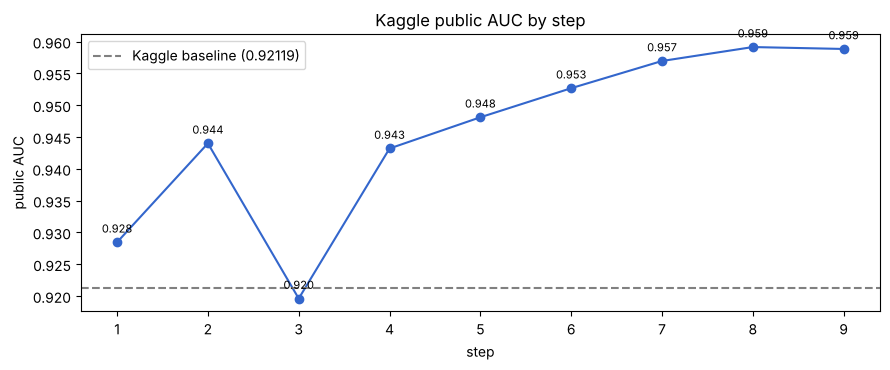

,step,model,public AUC
0,1,MLP-heavy blend,0.92846
1,2,"LightGBM cautious, no time proxies",0.94401
2,3,Random Forest,0.91961
3,4,LightGBM GOSS (best on validation),0.94320
4,5,LightGBM flexible,0.94811
5,6,Flexible ensemble + recent windows,0.95268
6,7,+ 1-hop neighbour features,0.95696
7,8,+ 2-hop neighbour features (FINAL),0.95915
8,9,+ neighbour spread (rejected),0.95885


In [28]:
kaggle = pd.DataFrame([
    ("1", "MLP-heavy blend", 0.92846),
    ("2", "LightGBM cautious, no time proxies", 0.94401),
    ("3", "Random Forest", 0.91961),
    ("4", "LightGBM GOSS (best on validation)", 0.94320),
    ("5", "LightGBM flexible", 0.94811),
    ("6", "Flexible ensemble + recent windows", 0.95268),
    ("7", "+ 1-hop neighbour features", 0.95696),
    ("8", "+ 2-hop neighbour features (FINAL)", 0.95915),
    ("9", "+ neighbour spread (rejected)", 0.95885),
], columns=["step", "model", "public AUC"])

plt.figure(figsize=(9, 3.8))
plt.plot(kaggle["step"], kaggle["public AUC"], marker="o", color="#36c")
plt.axhline(0.92119, ls="--", color="grey", label="Kaggle baseline (0.92119)")
for _, r in kaggle.iterrows():
    plt.annotate(f'{r["public AUC"]:.3f}', (r["step"], r["public AUC"]), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
plt.title("Kaggle public AUC by step")
plt.xlabel("step")
plt.ylabel("public AUC")
plt.legend()
plt.tight_layout()
plt.show()
kaggle

## 7.3 Feature importance of the final model

Which features the final model relies on (gain, averaged over 10 seeds of the
first configuration). Red bars mark graph features; the printout shows how many reach the top 20.

share of total gain from graph features: 0.176
share of total gain from own-transaction features: 0.824
graph features in the top 20: 0

Top 10 features (share of gain):
feat_55     10.0
feat_53      9.6
feat_14      6.5
feat_41      6.3
feat_90      5.2
feat_60      3.3
feat_5       3.2
feat_47      2.9
feat_132     2.1
feat_43      2.1
top 5 together: 37.5%

Highest-ranked graph features:
  rank 21: pin_feat_106 (0.8%)
  rank 23: dd_feat_76 (0.7%)
  rank 31: pout_feat_47 (0.5%)


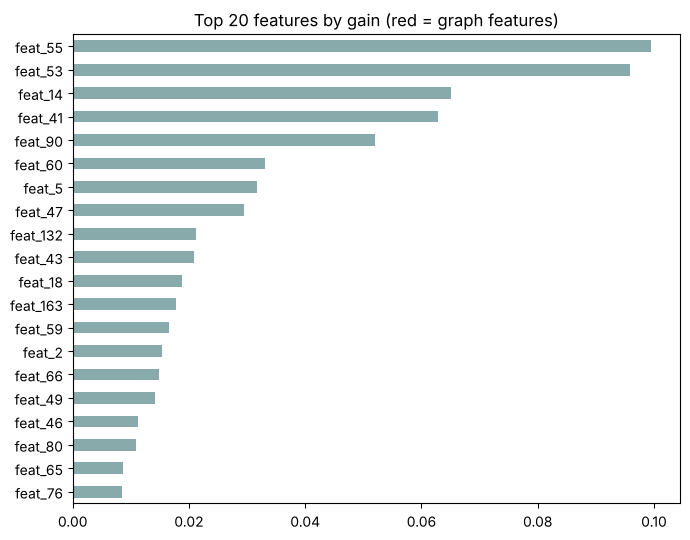


Total runtime: 29.5 minutes


In [29]:
importance = pd.Series(0.0, index=FINAL_FEATS)
for seed in seeds10:
    params = dict(CONFIGS["flex_ff0.3"][0])
    params["seed"] = seed
    model = lgb.train(params, lgb.Dataset(L[FINAL_FEATS], L["label"]), 100)
    importance += pd.Series(model.feature_importance("gain"), index=FINAL_FEATS)

importance = (importance / importance.sum()).sort_values(ascending=False)
GRAPH_FEATS = [c for c in FINAL_FEATS if c not in F]

is_graph = importance.index.isin(GRAPH_FEATS)
print("share of total gain from graph features:", round(importance[is_graph].sum(), 3))
print("share of total gain from own-transaction features:", round(importance[~is_graph].sum(), 3))
print("graph features in the top 20:", int(is_graph[:20].sum()))

print("\nTop 10 features (share of gain):")
print((importance.head(10) * 100).round(1).to_string())
print("top 5 together:", f"{importance.head(5).sum():.1%}")

print("\nHighest-ranked graph features:")
ranks = pd.Series(np.arange(1, len(importance) + 1), index=importance.index)
for name in [c for c in importance.index if c in GRAPH_FEATS][:3]:
    print(f"  rank {ranks[name]}: {name} ({importance[name]:.1%})")

top = importance.head(20).iloc[::-1]
colours = ["#c44" if c in GRAPH_FEATS else "#8aa" for c in top.index]
top.plot.barh(figsize=(7, 5.5), color=colours)
plt.title("Top 20 features by gain (red = graph features)")
plt.tight_layout()
plt.show()

print(f"\nTotal runtime: {(time.time() - start_time) / 60:.1f} minutes")

The own-transaction features dominate the top of the ranking, and the graph
features take about 18% of the total gain, spread thinly across ~500 columns.
So the neighbourhood information acts as a broad supporting signal rather than
a few key features, which fits the steady but modest Kaggle gains in steps 7
and 8.

# 8. Conclusion

* **Final model:** 30 LightGBM models (3 configurations x 10 seeds), trained on
  162 transaction features plus visible-neighbour graph features (1-hop in/out
  averages, differences from the neighbourhood, and 2-hop averages).
  Public AUC **0.95915**.
* **Biggest lessons:**
  1. Validation that cannot see a structural break is misleading. The model
     that topped my validation (MLP) was one of my weakest Kaggle submissions,
     and dropping it gave the largest single gain (+0.016, step 1 to step 2).
  2. Flexible trees generalised better than cautious ones to the changed test
     period (+0.004), and averaging several flexible models added +0.005.
  3. Neighbourhood features added a further +0.006 across steps 7 and 8. The
     model still relies mostly on each transaction's own features (about 82% of
     gain); the graph features contribute through many small splits rather than
     a few dominant ones.